# El compañero remoto y las cifras que no debo sumar

Categoría: **EDA (análisis exploratorio de datos)**. Corte documental: 15 de octubre de 2026.

Me pregunto qué cambia cuando separo casos, actualizaciones judiciales y tipos de dinero. No intento estimar cuántos trabajadores norcoreanos permanecen sin detectar ni producir una predicción.

## Ruta de lectura y vocabulario

Primero preparo los datos; después exploro el alcance de tres casos y compruebo qué sumas serían engañosas.

Una granja de portátiles es un lugar que aloja equipos a los que alguien accede desde fuera. Un dispositivo KVM permite controlar teclado, vídeo y ratón. Una acusación contiene alegaciones; no equivale a una sentencia. Un umbral es una cantidad mínima publicada, no un recuento exacto.

Uso dólares estadounidenses, sin convertirlos a euros: las cifras corresponden a periodos distintos.

## Origen y alcance

Selecciono cuatro comunicados del Departamento de Justicia estadounidense, no una muestra representativa. Transcribo manualmente doce cifras y conservo su calificador original. Dos comunicados corresponden al mismo caso Wang. No identifico las empresas afectadas, por lo que no puedo descontar posibles coincidencias entre casos. El archivo de fuentes permite revisar cada cifra. No infiero tendencias anuales de esta selección.

In [1]:
# importo las herramientas que necesito para leer, comprobar y representar mis datos
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# localizo los archivos tanto en el proyecto como junto a la copia publicada
raiz = Path.cwd()
ruta_datos = raiz / "data" if (raiz / "data/cifras_documentales.csv").exists() else raiz
datos = pd.read_csv(ruta_datos / "cifras_documentales.csv")
fuentes = pd.read_csv(ruta_datos / "fuentes.csv")
display(fuentes)
display(datos)

fuente_id,url,consulta
chapman_2024,https://www.justice.gov/archives/opa/pr/charges-and-seizures-brought-fraud-scheme-aimed-denying-revenue-workers-associated-north,2026-10-15
wang_2025,https://www.justice.gov/opa/pr/justice-department-announces-coordinated-nationwide-actions-combat-north-korean-remote,2026-10-15
wang_2026,https://www.justice.gov/opa/pr/two-us-nationals-sentenced-facilitating-fraudulent-remote-information-technology-worker,2026-10-15
texas_2026,https://www.justice.gov/opa/pr/justice-department-announces-coordinated-actions-combat-north-korean-remote-it-worker,2026-10-15


caso,fecha,metrica,valor,calificador,unidad,fuente_id,estado
chapman,2024-05-16,empresas,300,mas_de,empresas,chapman_2024,acusacion
chapman,2024-05-16,identidades,60,mas_de,personas,chapman_2024,acusacion
chapman,2024-05-16,ingresos,6800000,al_menos,USD,chapman_2024,acusacion
wang,2025-06-30,empresas,100,mas_de,empresas,wang_2025,acusacion
wang,2025-06-30,identidades,80,mas_de,personas,wang_2025,acusacion
wang,2025-06-30,danos,3000000,al_menos,USD,wang_2025,acusacion
wang,2026-04-15,empresas,100,mas_de,empresas,wang_2026,sentencia_dos_facilitadores
wang,2026-04-15,identidades,80,al_menos,personas,wang_2026,sentencia_dos_facilitadores
wang,2026-04-15,ingresos,5000000,mas_de,USD,wang_2026,sentencia_dos_facilitadores
texas,2026-10-13,empresas,70,mas_de,empresas,texas_2026,acusacion


## Preparación de datos

Compruebo que cada cifra tenga fuente, unidad y significado. Conservo las observaciones históricas para enseñar el cambio documental, pero elijo la última publicación para cada pareja de caso y métrica. No trato un dato ausente como cero.

In [2]:
# compruebo las claves antes de construir la tabla de observaciones vigentes
assert not datos.duplicated(["caso", "fecha", "metrica"]).any()
assert datos["valor"].gt(0).all()
assert datos["fuente_id"].isin(fuentes["fuente_id"]).all()
assert datos[columnas_requeridas := ["caso", "fecha", "metrica", "unidad", "calificador"]].notna().all().all()
datos["fecha"] = pd.to_datetime(datos["fecha"])
actuales = datos.sort_values("fecha").drop_duplicates(["caso", "metrica"], keep="last")
display(actuales)

caso,fecha,metrica,valor,calificador,unidad,fuente_id,estado
chapman,2024-05-16,empresas,300,mas_de,empresas,chapman_2024,acusacion
chapman,2024-05-16,identidades,60,mas_de,personas,chapman_2024,acusacion
chapman,2024-05-16,ingresos,6800000,al_menos,USD,chapman_2024,acusacion
wang,2025-06-30,danos,3000000,al_menos,USD,wang_2025,acusacion
wang,2026-04-15,empresas,100,mas_de,empresas,wang_2026,sentencia_dos_facilitadores
wang,2026-04-15,identidades,80,al_menos,personas,wang_2026,sentencia_dos_facilitadores
wang,2026-04-15,ingresos,5000000,mas_de,USD,wang_2026,sentencia_dos_facilitadores
texas,2026-10-13,empresas,70,mas_de,empresas,texas_2026,acusacion
texas,2026-10-13,ingresos,3000000,aproximadamente,USD,texas_2026,acusacion
texas,2026-10-13,dispositivos,187,aproximadamente,equipos_incluidos_kvm,texas_2026,intervencion


## EDA: tres casos, sin una curva de crecimiento

Comparo únicamente umbrales publicados de empresas. Las barras no son tamaños exactos ni una serie temporal: cada expediente cubre una red y un periodo diferentes. Leo «más de 300», «más de 100» y «más de 70». No puedo concluir que el fenómeno disminuya porque el último expediente tenga una cifra menor.

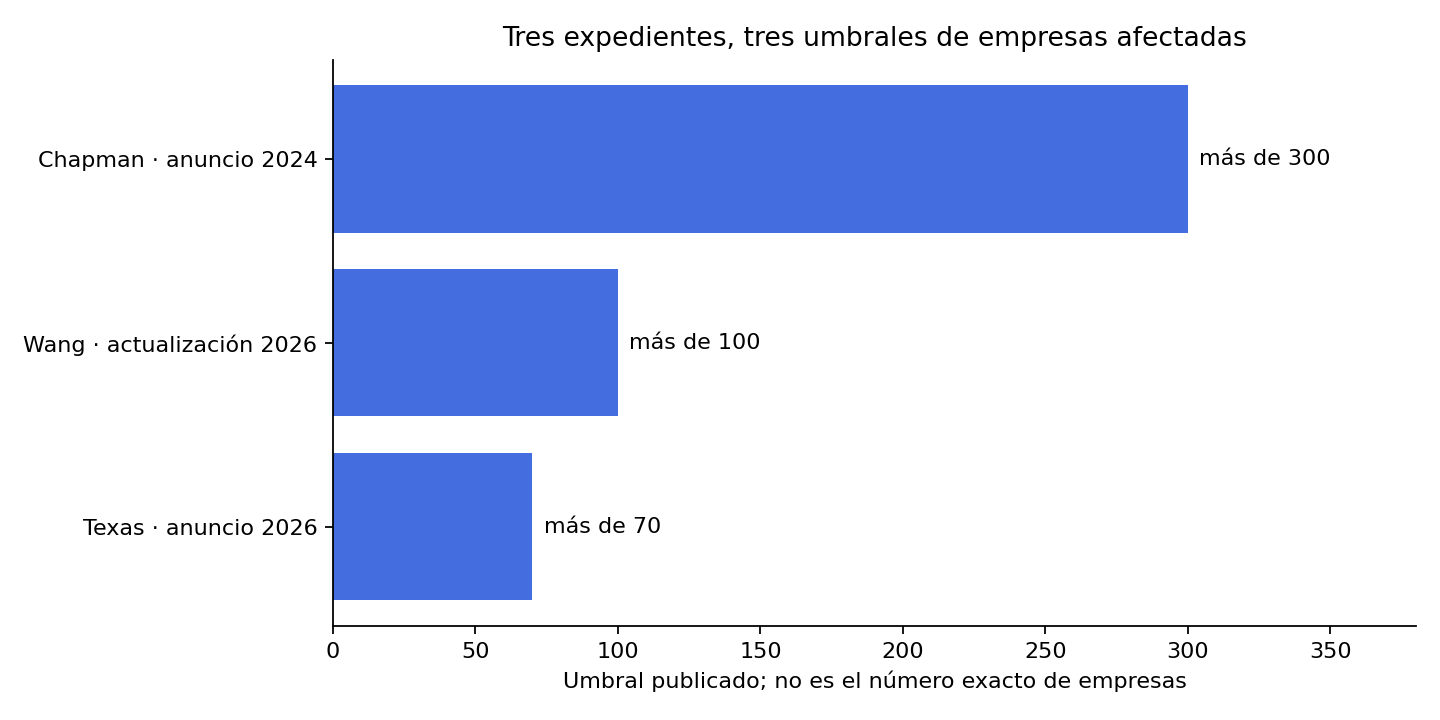

In [3]:
# represento los umbrales sin convertirlos en recuentos exactos
empresas = actuales.loc[actuales["metrica"].eq("empresas")].set_index("caso").loc[["chapman", "wang", "texas"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(["Chapman · anuncio 2024", "Wang · actualización 2026", "Texas · anuncio 2026"], empresas["valor"], color="#446ddf")
for posicion, valor in enumerate(empresas["valor"]):
    ax.text(valor + 4, posicion, f"más de {valor}", va="center")
ax.set_xlim(0, 380)
ax.invert_yaxis()
ax.set_title("Tres expedientes, tres umbrales de empresas afectadas")
ax.set_xlabel("Umbral publicado; no es el número exacto de empresas")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
carpeta_graficos = raiz / "graficos"
carpeta_graficos.mkdir(exist_ok=True)
fig.savefig(carpeta_graficos / "empresas_por_caso.png", dpi=160)
plt.show()

## Una noticia nueva puede ser el mismo caso

En Wang encuentro un anuncio de acusaciones en junio de 2025 y sentencias de dos facilitadores en abril de 2026. Ambos hablan de más de cien empresas. Si sumara las noticias como incidentes nuevos, duplicaría la misma referencia. La sentencia de dos facilitadores tampoco resuelve por sí sola la situación de todos los demás acusados.

In [4]:
# cuantifico la duplicación de referencias, sin llamarla un total de víctimas
bruto = datos.loc[datos["metrica"].eq("empresas"), "valor"].sum()
depurado = empresas["valor"].sum()
exceso = bruto - depurado
print(f"Suma ingenua de referencias: {bruto}")
print(f"Suma tras quitar la actualización repetida: {depurado}")
print(f"Referencia duplicada: {exceso}; exceso aritmético: {exceso / depurado:.1%}")
print("Ninguna de las dos sumas es un recuento válido de empresas únicas.")
assert exceso == 100

Suma ingenua de referencias: 570
Suma tras quitar la actualización repetida: 470
Referencia duplicada: 100; exceso aritmético: 21.3%
Ninguna de las dos sumas es un recuento válido de empresas únicas.


## El dinero necesita apellido

Los tres millones de daños mencionados en Wang en 2025 no son sus ingresos: incluyen costes y pérdidas de los empleadores. La actualización de 2026 menciona más de cinco millones de ingresos. No son dos mediciones sucesivas de la misma variable. Tampoco divido ingresos por empresas o identidades: combinar límites y cantidades aproximadas produciría una falsa media.

En Texas, 187 se refiere aproximadamente a portátiles y dispositivos de control remoto. No lo convierto en personas, puestos de trabajo ni empresas.

In [5]:
# separo ingresos y daños para impedir una suma de conceptos distintos
dinero = actuales.loc[actuales["unidad"].eq("USD"), ["caso", "metrica", "valor", "calificador", "fecha"]].copy()
dinero["millones_usd"] = dinero["valor"] / 1_000_000
display(dinero)
assert set(dinero["metrica"]) == {"ingresos", "danos"}
actuales.to_csv(raiz / "cifras_depuradas.csv", index=False)

caso,metrica,valor,calificador,fecha,millones_usd
chapman,ingresos,6800000,al_menos,2024-05-16,6.8
wang,danos,3000000,al_menos,2025-06-30,3.0
wang,ingresos,5000000,mas_de,2026-04-15,5.0
texas,ingresos,3000000,aproximadamente,2026-10-13,3.0


## Conclusión y límites

Identifico tres casos y una actualización, no cuatro redes independientes. Compruebo que una suma ingenua repite un umbral de cien empresas y que mezclar ingresos con daños cambia el significado del dinero.

La infraestructura local aparece como pieza relevante en las fuentes; interpreto que la distancia física del trabajador no elimina la necesidad de colaboradores y equipos. No mido su importancia relativa frente a otros mecanismos.

No conozco el universo de casos, las empresas únicas, la incidencia anual, el número de personas detrás de cada equipo ni el porcentaje de contrataciones fraudulentas. Por eso no calculo una tasa de crecimiento ni una probabilidad de que un compañero sea un impostor.